# 02. Praproses Data

## Proyek Akhir Pembelajaran Mesin (INF62325)

### Analisis Properti Rumah dengan Implementasi Algoritma K-Means Berdasarkan Karakteristik dan Harga di Wilayah Jabodetabek

**Kelas:** Informatika 5A

**Anggota Kelompok:**
- Nisa Naila (2488010024)
- Najwa Ramadhan (2488010001)
- Haikal Azkal Azkiya (2488010038)

**Dataset:** Jabodetabek House Price

**Metode:** K-Means Clustering

## Tujuan Praproses

Tahap praproses bertujuan untuk menghasilkan dataset
yang bersih, konsisten, dan siap digunakan dalam
eksperimen algoritma K-Means pada ketiga varian.

Proses meliputi normalisasi data, penghapusan
duplikat, seleksi fitur, penanganan missing value,
pembatasan outlier menggunakan metode IQR,
serta penyimpanan dataset akhir.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from google.colab import files

os.makedirs("data", exist_ok=True)
os.makedirs("gambar", exist_ok=True)

SEED = 42
IQR_PENGALI = 1.5
ID_COL = "ads_id"

pd.set_option("display.max_columns", None)

print("Library berhasil dimuat.")
print("Versi scikit-learn:", sklearn.__version__)

Library berhasil dimuat.
Versi scikit-learn: 1.6.1


## 2.1 Import Dataset

Dataset yang digunakan merupakan dataset hasil
eksplorasi pada tahap sebelumnya, yaitu
hasil_pengolahan.csv.

In [2]:
uploaded = files.upload()

Saving hasil_pengolahan.csv to hasil_pengolahan.csv


In [3]:
df = pd.read_csv("hasil_pengolahan.csv")

print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())

Jumlah baris: 3553
Jumlah kolom: 27


,url,price_in_rp,title,address,district,city,lat,long,facilities,property_type,ads_id,bedrooms,bathrooms,land_size_m2,building_size_m2,carports,certificate,electricity,maid_bedrooms,maid_bathrooms,floors,building_age,year_built,property_condition,building_orientation,garages,furnishing
0,https://www.rumah123.com/properti/bekasi/hos11...,2.990000e+09,Rumah cantik Sumarecon Bekasi\nLingkungan asri...,"Summarecon Bekasi, Bekasi",Summarecon Bekasi,Bekasi,-6.223945,106.986275,"Tempat Jemuran, Jalur Telepon, Taman, Taman",rumah,hos11360272,4.0,4.0,239.0,272.0,0.0,shm - sertifikat hak milik,4400 mah,0.0,1.0,2.0,5.0,2017.0,bagus,NaN,0.0,unfurnished
1,https://www.rumah123.com/properti/bekasi/hos10...,1.270000e+09,"Rumah Kekinian, Magenta Summarecon Bekasi","Summarecon Bekasi, Bekasi",Summarecon Bekasi,Bekasi,-6.223945,106.986275,Taman,rumah,hos10680347,3.0,2.0,55.0,69.0,1.0,hgb - hak guna bangunan,2200 mah,0.0,0.0,2.0,NaN,NaN,bagus,NaN,0.0,NaN
2,https://www.rumah123.com/properti/bekasi/hos10...,1.950000e+09,Rumah Cantik 2 Lantai Cluster Bluebell Summare...,"Summarecon Bekasi, Bekasi",Summarecon Bekasi,Bekasi,-6.223945,106.986275,"Jogging Track, Kolam Renang, Masjid, Taman,...",rumah,hos10685867,3.0,3.0,119.0,131.0,1.0,hgb - hak guna bangunan,2200 mah,1.0,1.0,2.0,NaN,NaN,bagus,NaN,1.0,unfurnished
3,https://www.rumah123.com/properti/bekasi/hos10...,3.300000e+09,Rumah Mewah 2Lantai L10x18 C di Cluster VERNON...,"Summarecon Bekasi, Bekasi",Summarecon Bekasi,Bekasi,-6.223945,106.986275,"Jalur Telepon, Jogging Track, Track Lari, K...",rumah,hos10927790,3.0,3.0,180.0,174.0,0.0,shm - sertifikat hak milik,3500 mah,1.0,1.0,2.0,6.0,2016.0,bagus sekali,utara,2.0,unfurnished
4,https://www.rumah123.com/properti/bekasi/hos10...,4.500000e+09,"Rumah Hoek di Cluster Maple Summarecon Bekasi,...","Summarecon Bekasi, Bekasi",Summarecon Bekasi,Bekasi,-6.223945,106.986275,"Jogging Track, Kolam Renang, Taman, Jalur Te...",rumah,hos10785530,4.0,3.0,328.0,196.0,2.0,shm - sertifikat hak milik,3500 mah,1.0,1.0,2.0,9.0,2013.0,bagus,utara,1.0,unfurnished


## 2.2 Normalisasi dan Penghapusan Duplikat

Normalisasi URL dan fasilitas dilakukan dengan
mengacu pada hasil eksplorasi sebelumnya.
Selanjutnya, baris duplikat identik dihapus agar
tidak memengaruhi pembentukan cluster.

In [4]:
df_bersih = df.copy()

# Normalisasi URL
df_bersih["url"] = (
    df_bersih["url"].str.split("#").str[0]
)

# Normalisasi fasilitas
def normalisasi_facilities(nilai):
    if pd.isna(nilai):
        return nilai

    fasilitas = [
        item.strip().lower()
        for item in nilai.split(",")
        if item.strip()
    ]

    return ", ".join(sorted(fasilitas))

df_bersih["facilities"] = (
    df_bersih["facilities"]
    .apply(normalisasi_facilities)
)

# Penghapusan duplikat
jumlah_sebelum = len(df_bersih)

df_bersih = (
    df_bersih.drop_duplicates()
    .reset_index(drop=True)
)

jumlah_sesudah = len(df_bersih)

print("Jumlah data sebelum:", jumlah_sebelum)
print("Jumlah data sesudah:", jumlah_sesudah)
print("Duplikat dihapus:",
      jumlah_sebelum - jumlah_sesudah)
print("Duplikat tersisa:",
      df_bersih.duplicated().sum())

Jumlah data sebelum: 3553
Jumlah data sesudah: 3470
Duplikat dihapus: 83
Duplikat tersisa: 0


## 2.3 Seleksi Fitur

Seleksi fitur dilakukan berdasarkan relevansi
variabel terhadap tujuan pengelompokan properti.

Fitur yang digunakan meliputi harga rumah,
luas tanah, luas bangunan, jumlah kamar tidur,
jumlah kamar mandi, dan jumlah lantai.

Kolom identitas dan kolom yang tidak relevan
tidak digunakan dalam pembentukan cluster.

In [5]:
fitur = [
    "price_in_rp",
    "land_size_m2",
    "building_size_m2",
    "bedrooms",
    "bathrooms",
    "floors"
]

# Menyimpan identitas secara terpisah
ids = df_bersih[ID_COL].copy()

# Mengambil fitur utama K-Means
df_model = df_bersih[fitur].copy()

# Memastikan seluruh fitur bertipe numerik
for kolom in fitur:
    df_model[kolom] = pd.to_numeric(
        df_model[kolom],
        errors="coerce"
    )

print("Ukuran dataset:", df_model.shape)
print("Jumlah fitur:", len(fitur))

display(df_model.head())

Ukuran dataset: (3470, 6)
Jumlah fitur: 6


,price_in_rp,land_size_m2,building_size_m2,bedrooms,bathrooms,floors
0,2.990000e+09,239.0,272.0,4.0,4.0,2.0
1,1.270000e+09,55.0,69.0,3.0,2.0,2.0
2,1.950000e+09,119.0,131.0,3.0,3.0,2.0
3,3.300000e+09,180.0,174.0,3.0,3.0,2.0
4,4.500000e+09,328.0,196.0,4.0,3.0,2.0


## 2.4 Penanganan Missing Value

Nilai kosong pada fitur numerik ditangani
menggunakan imputasi median karena median
lebih tahan terhadap pengaruh nilai ekstrem.

In [6]:
print("Missing value sebelum imputasi:")

display(
    df_model.isna().sum().to_frame(
        "Jumlah Missing Value"
    )
)

Missing value sebelum imputasi:


,Jumlah Missing Value
price_in_rp,0
land_size_m2,2
building_size_m2,2
bedrooms,33
bathrooms,28
floors,6


In [7]:
hasil_imputasi = []

for kolom in fitur:
    jumlah_missing = df_model[kolom].isna().sum()
    median = df_model[kolom].median()

    df_model[kolom] = (
        df_model[kolom].fillna(median)
    )

    hasil_imputasi.append({
        "Fitur": kolom,
        "Jumlah Imputasi": jumlah_missing,
        "Median": median
    })

tabel_imputasi = pd.DataFrame(hasil_imputasi)

display(tabel_imputasi)

print("Total missing value setelah imputasi:",
      df_model.isna().sum().sum())

,Fitur,Jumlah Imputasi,Median
0,price_in_rp,0,1.500000e+09
1,land_size_m2,2,1.080000e+02
2,building_size_m2,2,1.100000e+02
3,bedrooms,33,3.000000e+00
4,bathrooms,28,2.000000e+00
5,floors,6,2.000000e+00


Total missing value setelah imputasi: 0


## 2.5 Penanganan Outlier

Penanganan outlier dilakukan menggunakan metode
Interquartile Range (IQR) dengan pengali 1,5.

Nilai yang berada di luar batas bawah dan batas
atas dibatasi menggunakan metode clipping.

Metode ini digunakan untuk mengurangi pengaruh
nilai ekstrem terhadap pembentukan pusat cluster
tanpa menghilangkan baris data properti.

In [8]:
df_sebelum_clipping = df_model.copy()

hasil_outlier = []

for kolom in fitur:

    Q1 = df_model[kolom].quantile(0.25)
    Q3 = df_model[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - IQR_PENGALI * IQR
    batas_atas = Q3 + IQR_PENGALI * IQR

    jumlah_outlier = (
        (df_model[kolom] < batas_bawah) |
        (df_model[kolom] > batas_atas)
    ).sum()

    df_model[kolom] = df_model[kolom].clip(
        lower=batas_bawah,
        upper=batas_atas
    )

    hasil_outlier.append({
        "Fitur": kolom,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Dibatasi": jumlah_outlier,
        "Persentase (%)": round(
            jumlah_outlier / len(df_model) * 100,
            2
        )
    })

tabel_outlier = pd.DataFrame(hasil_outlier)

display(tabel_outlier)

print("Total nilai yang dibatasi:",
      tabel_outlier["Jumlah Dibatasi"].sum())

print("Jumlah baris setelah clipping:",
      len(df_model))

,Fitur,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Dibatasi,Persentase (%)
0,price_in_rp,8.000000e+08,3.550000e+09,2.750000e+09,-3.325000e+09,7.675000e+09,376,10.84
1,land_size_m2,7.500000e+01,1.877500e+02,1.127500e+02,-9.412500e+01,3.568750e+02,378,10.89
2,building_size_m2,6.525000e+01,2.000000e+02,1.347500e+02,-1.368750e+02,4.021250e+02,326,9.39
3,bedrooms,2.000000e+00,4.000000e+00,2.000000e+00,-1.000000e+00,7.000000e+00,37,1.07
4,bathrooms,2.000000e+00,3.000000e+00,1.000000e+00,5.000000e-01,4.500000e+00,195,5.62
5,floors,1.000000e+00,2.000000e+00,1.000000e+00,-5.000000e-01,3.500000e+00,22,0.63


Total nilai yang dibatasi: 1334
Jumlah baris setelah clipping: 3470


## 2.6 Visualisasi Hasil Penanganan Outlier

Visualisasi dilakukan untuk membandingkan distribusi
fitur sebelum dan sesudah pembatasan outlier.

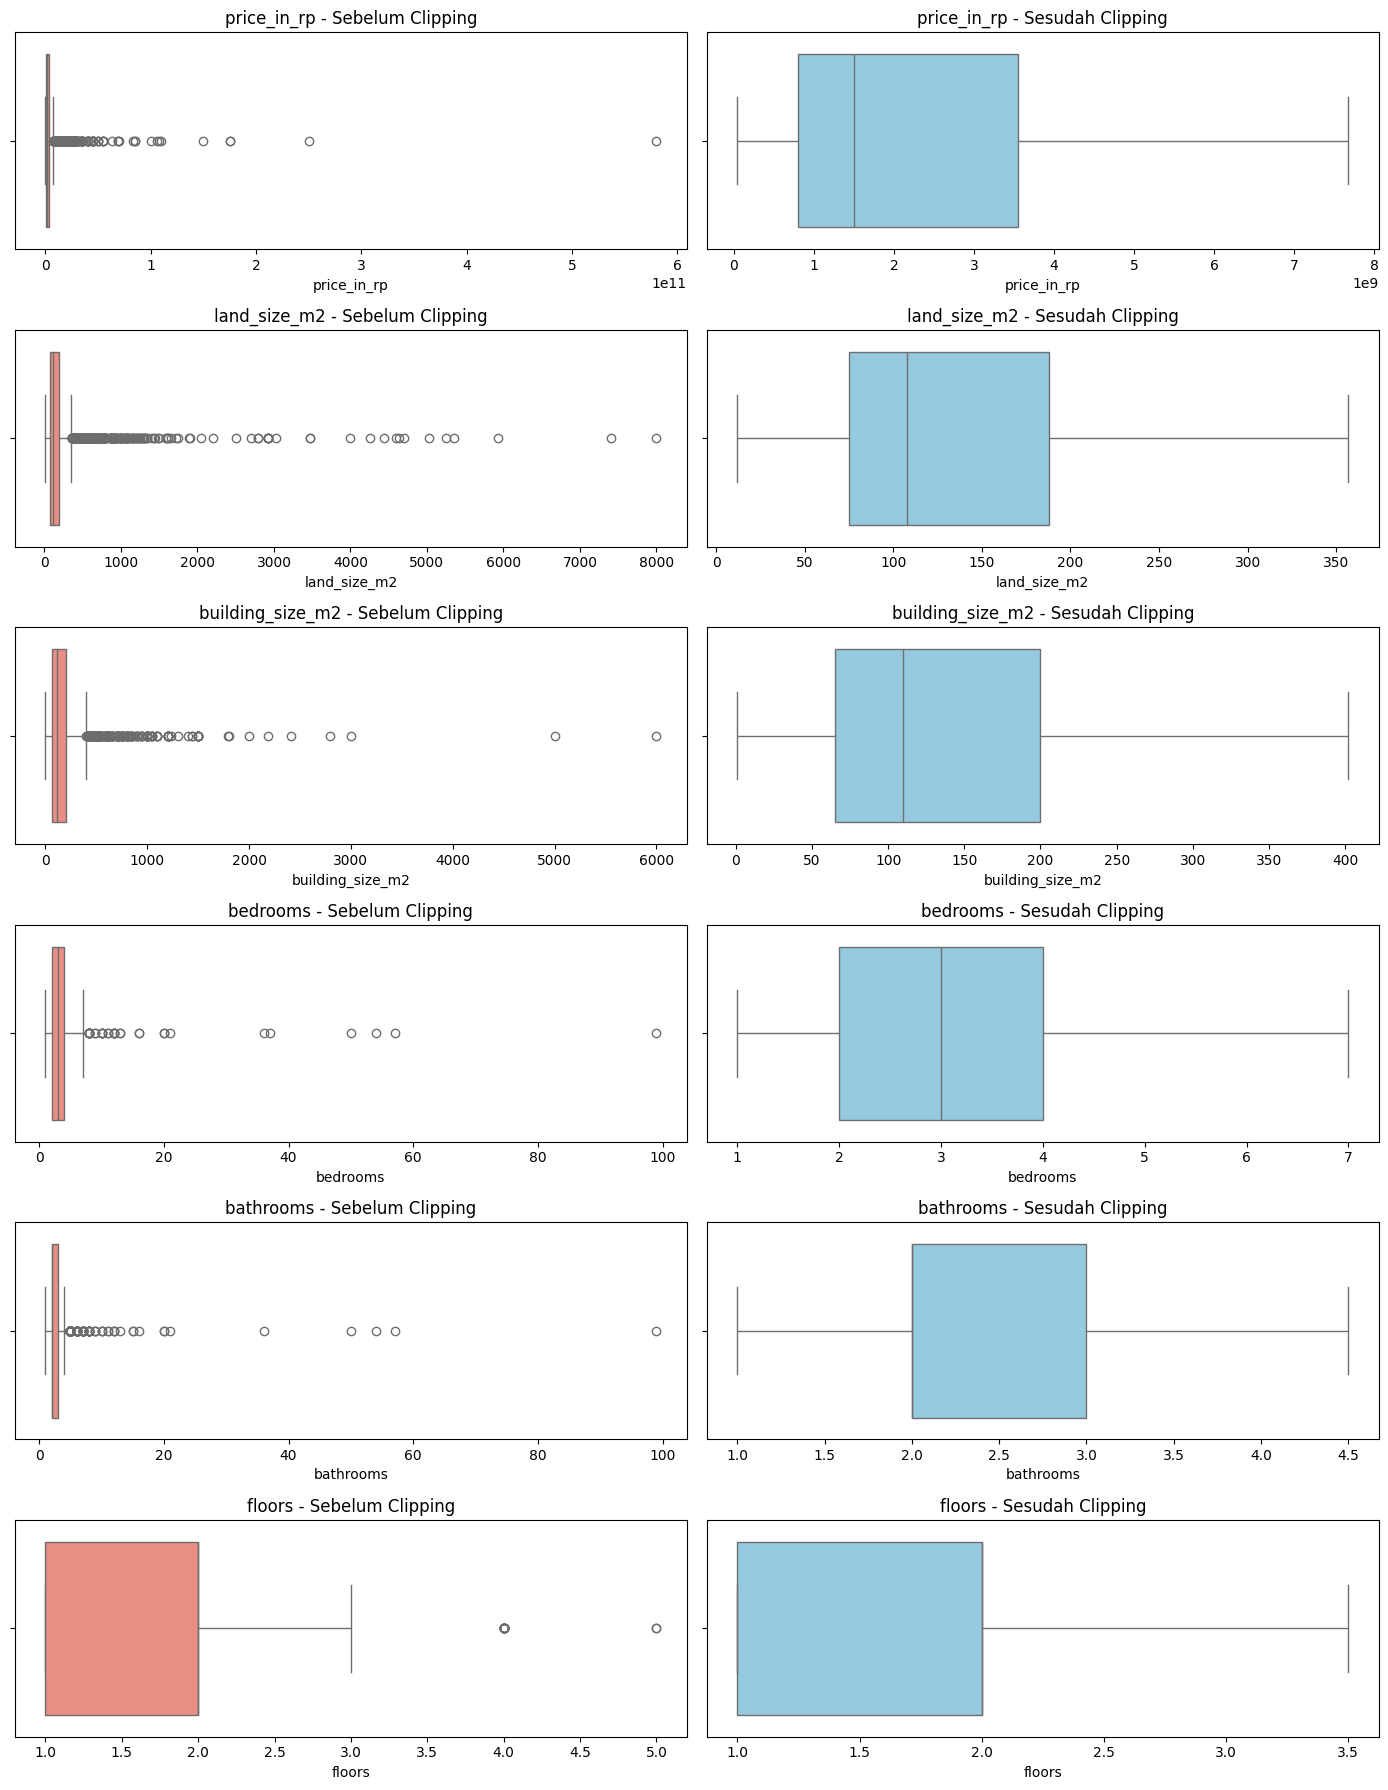

In [9]:
fig, axes = plt.subplots(
    len(fitur), 2,
    figsize=(14, 18)
)

for i, kolom in enumerate(fitur):

    sns.boxplot(
        x=df_sebelum_clipping[kolom],
        ax=axes[i, 0],
        color="salmon"
    )

    axes[i, 0].set_title(
        f"{kolom} - Sebelum Clipping"
    )

    sns.boxplot(
        x=df_model[kolom],
        ax=axes[i, 1],
        color="skyblue"
    )

    axes[i, 1].set_title(
        f"{kolom} - Sesudah Clipping"
    )

plt.tight_layout()

plt.savefig(
    "gambar/perbandingan_outlier.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 2.7 Validasi Dataset Akhir

Validasi dilakukan untuk memastikan seluruh fitur
bertipe numerik, tidak memiliki nilai kosong,
serta tidak mengandung nilai tak hingga.

In [10]:
print("=" * 50)
print("VALIDASI DATASET AKHIR")
print("=" * 50)

print("Jumlah baris:", df_model.shape[0])
print("Jumlah fitur:", df_model.shape[1])
print("Missing value:", df_model.isna().sum().sum())
print("Nilai infinite:",
      np.isinf(df_model.to_numpy()).sum())

print("\nTipe data setiap fitur:")
print(df_model.dtypes)

assert df_model.isna().sum().sum() == 0
assert np.isfinite(df_model.to_numpy()).all()

print("\nValidasi berhasil.")

display(df_model.head())
display(df_model.describe().T)

VALIDASI DATASET AKHIR
Jumlah baris: 3470
Jumlah fitur: 6
Missing value: 0
Nilai infinite: 0

Tipe data setiap fitur:
price_in_rp         float64
land_size_m2        float64
building_size_m2    float64
bedrooms            float64
bathrooms           float64
floors              float64
dtype: object

Validasi berhasil.


,price_in_rp,land_size_m2,building_size_m2,bedrooms,bathrooms,floors
0,2.990000e+09,239.0,272.0,4.0,4.0,2.0
1,1.270000e+09,55.0,69.0,3.0,2.0,2.0
2,1.950000e+09,119.0,131.0,3.0,3.0,2.0
3,3.300000e+09,180.0,174.0,3.0,3.0,2.0
4,4.500000e+09,328.0,196.0,4.0,3.0,2.0


,count,mean,std,min,25%,50%,75%,max
price_in_rp,3470.0,2.557513e+09,2.351444e+09,42000000.0,8.000000e+08,1.500000e+09,3.550000e+09,7.675000e+09
land_size_m2,3470.0,1.472319e+02,9.752829e+01,12.0,7.500000e+01,1.080000e+02,1.877500e+02,3.568750e+02
building_size_m2,3470.0,1.560996e+02,1.173488e+02,1.0,6.525000e+01,1.100000e+02,2.000000e+02,4.021250e+02
bedrooms,3470.0,3.205476e+00,1.092243e+00,1.0,2.000000e+00,3.000000e+00,4.000000e+00,7.000000e+00
bathrooms,3470.0,2.443660e+00,1.071357e+00,1.0,2.000000e+00,2.000000e+00,3.000000e+00,4.500000e+00
floors,3470.0,1.762248e+00,6.259854e-01,1.0,1.000000e+00,2.000000e+00,2.000000e+00,3.500000e+00


## 2.8 Penyimpanan Dataset Bersih

Dataset hasil praproses disimpan dalam format CSV
untuk digunakan secara bersama oleh ketiga anggota
pada eksperimen K-Means.

Standardisasi dilakukan pada tahap eksperimen
menggunakan StandardScaler sesuai template dosen.

In [11]:
# Menyiapkan dataset akhir
data_akhir = df_model.copy()

# Menambahkan identitas properti untuk keterlacakan
data_akhir.insert(
    0,
    ID_COL,
    ids.to_numpy()
)

# Menyimpan dataset
data_akhir.to_csv(
    "data/data_bersih.csv",
    index=False
)

print("Dataset berhasil disimpan.")
print("Lokasi: data/data_bersih.csv")
print("Ukuran:", data_akhir.shape)

display(data_akhir.head())

Dataset berhasil disimpan.
Lokasi: data/data_bersih.csv
Ukuran: (3470, 7)


,ads_id,price_in_rp,land_size_m2,building_size_m2,bedrooms,bathrooms,floors
0,hos11360272,2.990000e+09,239.0,272.0,4.0,4.0,2.0
1,hos10680347,1.270000e+09,55.0,69.0,3.0,2.0,2.0
2,hos10685867,1.950000e+09,119.0,131.0,3.0,3.0,2.0
3,hos10927790,3.300000e+09,180.0,174.0,3.0,3.0,2.0
4,hos10785530,4.500000e+09,328.0,196.0,4.0,3.0,2.0


In [12]:
files.download("data/data_bersih.csv")
files.download("gambar/perbandingan_outlier.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 2.9 Kesimpulan Praproses

Berdasarkan hasil praproses, dataset awal yang
terdiri atas 3.553 baris dan 27 kolom telah
melalui normalisasi, penghapusan duplikat,
seleksi fitur, imputasi median, serta pembatasan
outlier menggunakan metode IQR.

Sebanyak 83 baris duplikat dihapus, sehingga
jumlah data menjadi 3.470 baris. Sebanyak
71 nilai kosong ditangani menggunakan imputasi
median, sedangkan 1.334 nilai ekstrem dibatasi
menggunakan metode clipping IQR.

Dataset akhir terdiri atas enam fitur numerik
dan satu kolom identitas properti. Dataset
disimpan dalam berkas data_bersih.csv untuk
digunakan pada ketiga varian eksperimen K-Means.

Standardisasi fitur dilakukan pada tahap
eksperimen agar perbedaan satuan antarfitur
tidak mendominasi perhitungan jarak.